In [1]:
import sys
import os
import math
from typing import NamedTuple

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer

from models import clm
from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(clm)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/JetBrains/DataSpell/MSc_Thesis/worm-2025-fieseler/import/models/hgm.py'>

# Functions

In [3]:
class Lambdas(NamedTuple):
	loss_lambdas: tuple[float, float]
	reg_lambdas: tuple[float, float]
	cca_lambdas: tuple[float, float]

class PrepData(NamedTuple):
	N_mean: tuple[float, ...]
	N_std: tuple[float, ...]
	B_hl_mean: tuple[float, ...] | None = None
	B_hl_std: tuple[float, ...] | None = None

In [4]:
def train_joint_model(model, splits, N, B_ll, B_hl, hyperparameters=None):
	# Hyperparamters ============
	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1), jax.random.PRNGKey(2), jax.random.PRNGKey(3)

	if hyperparameters is None:
		hyperparameters = {
			'max_epochs': 10000,
			'max_patience': 100,
			'learning_rate': 0.001,
			'w1_reg_lambda': 1E-3,
			'w2_reg_lambda': 5E-2,
			'ccaunit_lambda': 0.7,
			'ccadiag_lambda': 0.5,
			'loss1_lambda': 0.7,
			'loss2_lambda': 0.3,
			'dimensions': 1
		}

	max_epochs = hyperparameters['max_epochs']
	max_patience = hyperparameters['max_patience']
	optimizer = optax.adam(hyperparameters['learning_rate'])
	n_dimensions = hyperparameters['dimensions']

	lambdas = Lambdas(
		loss_lambdas=(hyperparameters['loss1_lambda'], hyperparameters['loss2_lambda']),
		reg_lambdas=(hyperparameters['w1_reg_lambda'], hyperparameters['w2_reg_lambda']),
		cca_lambdas=(hyperparameters['ccaunit_lambda'], hyperparameters['ccadiag_lambda'])
	)
	# ===========================

	n_neurons = N.shape[1]
	n_behaviors_hl = B_hl.shape[1]
	n_behaviors_ll = B_ll.shape[1]

	# training loop =======================================
	params_per_split = list()
	neuron_scores_per_split = list()
	losses_per_split = list()
	losses_tr_per_split = list()
	mse_losses_per_split = list()
	mse_losses_tr_per_split = list()
	__grads_per_split = list()
	for train, test in splits:
		# splitting and initializing ========================== (this also moves the data to the GPU)
		N_train, N_test = jnp.array(N[train]), jnp.array(N[test])
		B_hl_train, B_hl_test = jnp.array(B_hl[train]), jnp.array(B_hl[test])
		B_ll_train, B_ll_test = jnp.array(B_ll[train]), jnp.array(B_ll[test])

		prep_data_train = PrepData(
			N_mean=tuple((map(float, N_train.mean(axis=0)))),
			N_std=tuple((map(float, jnp.where((N_std := jnp.std(N_train, axis=0)) == 0.0, 1.0, N_std)))),
			B_hl_mean=tuple((map(float, B_hl_train.mean(axis=0)))),
			B_hl_std=tuple((map(float, jnp.where((B_hl_std := jnp.std(B_hl_train, axis=0)) == 0.0, 1.0, B_hl_std))))
		)
		prep_data_test = PrepData(
			N_mean=tuple((map(float, N_test.mean(axis=0)))),
			N_std=tuple((map(float, jnp.where((N_std := jnp.std(N_test, axis=0)) == 0.0, 1.0, N_std)))),
			B_hl_mean=tuple((map(float, B_hl_test.mean(axis=0)))),
			B_hl_std=tuple((map(float, jnp.where((B_hl_std := jnp.std(B_hl_test, axis=0)) == 0.0, 1.0, B_hl_std))))
		)

		params = model.init_params(seeds,
								   (n_neurons, n_dimensions),
								   (n_behaviors_hl, n_dimensions),
								   (n_behaviors_ll, n_neurons),
								   * ((n_dimensions, n_neurons),) if model.get_type() else ())
		opt_state = optimizer.init(params)
		# ===========================================================================================

		losses = [model.loss_fn(params, N_test, B_ll_test, B_hl_test, lambdas, prep_data_test).item()]
		losses_tr = [model.loss_fn(params, N_train, B_ll_train, B_hl_train, lambdas, prep_data_train).item()]
		mse_losses = [model.mse_loss_fn(params, N_test, B_ll_test, prep_data_test).item()]
		mse_losses_tr = [model.mse_loss_fn(params, N_train, B_ll_train, prep_data_train).item()]
		__grads = list()

		best_params = params
		best_loss = sys.float_info.max
		best_loss_tr = sys.float_info.max
		best_mse_loss = sys.float_info.max
		best_mse_loss_tr = sys.float_info.max

		patience = 0
		for epoch in range(max_epochs):
			params, opt_state, __grad = model.update(optimizer.update, opt_state, params, N_train, B_ll_train, B_hl_train, lambdas, prep_data_train)

			loss = model.loss_fn(params, N_test, B_ll_test, B_hl_test, lambdas, prep_data_test).item()
			loss_tr = model.loss_fn(params, N_train, B_ll_train, B_hl_train, lambdas, prep_data_train).item()
			mse_loss = model.mse_loss_fn(params, N_test, B_ll_test, prep_data_test).item()
			mse_loss_tr = model.mse_loss_fn(params, N_train, B_ll_train, prep_data_train).item()
			__grads.append(__grad)

			# early stopping ================
			if loss < best_loss:
				patience = 0

				best_params = params
				best_loss = loss
				best_loss_tr = loss_tr
				best_mse_loss = mse_loss
				best_mse_loss_tr = mse_loss_tr
			else:
				patience += 1
				if patience > max_patience:
					params = best_params
					losses = losses + [best_loss for _ in range(max_epochs - epoch)]
					losses_tr = losses_tr + [best_loss_tr for _ in range(max_epochs - epoch)]
					mse_losses = mse_losses + [best_mse_loss for _ in range(max_epochs - epoch)]
					mse_losses_tr = mse_losses_tr + [best_mse_loss_tr for _ in range(max_epochs - epoch)]
					break

			losses.append(loss)
			losses_tr.append(loss_tr)
			mse_losses.append(mse_loss)
			mse_losses_tr.append(mse_loss_tr)
			# ===============================

		params_per_split.append(params)
		losses_per_split.append(losses)
		losses_tr_per_split.append(losses_tr)
		mse_losses_per_split.append(mse_losses)
		mse_losses_tr_per_split.append(mse_losses_tr)
		__grads_per_split.append(__grads)

		# predicting and scoring ========================================================================
		score_per_neuron = model.score_fn(params, N_test, B_ll_test, prep_data_test)
		neuron_scores_per_split.append(score_per_neuron)
		# ===============================================================================================

	# =====================================================

	return params_per_split, np.array(neuron_scores_per_split), np.array(losses_per_split), np.array(losses_tr_per_split), np.array(mse_losses_per_split), np.array(mse_losses_tr_per_split), __grads_per_split

In [5]:
def train_joint_models(model, filenames, discrete_states, eigenworms, traces):
	models_params = list()
	models_scores = list()
	models_losses = list()
	models_losses_tr = list()
	models_mse_losses = list()
	models_mse_losses_tr = list()
	__models_grads = list()

	for i in range(len(filenames)):
		print(f'{i+1}/{len(filenames)}: {filenames[i]}  ', end='')

		splits = list(StratifiedKFold(n_splits=5).split(np.zeros(traces[i].shape[0]), discrete_states[i]['REV'].values))

		(params_per_split,
		 neuron_scores_per_split,
		 losses_per_split, losses_tr_per_split,
		 mse_losses_per_split, mse_losses_tr_per_split,
		 __grads_per_split) = train_joint_model(model, splits,
												jnp.array(traces[i].values),
												jnp.array(eigenworms[i].values),
												jnp.array(discrete_states[i].values))

		models_params.append(params_per_split)
		models_scores.append(neuron_scores_per_split)
		models_losses.append(losses_per_split)
		models_losses_tr.append(losses_tr_per_split)
		models_mse_losses.append(mse_losses_per_split)
		models_mse_losses_tr.append(mse_losses_tr_per_split)
		__models_grads.append(__grads_per_split)

	return models_params, models_scores, models_losses, models_losses_tr, models_mse_losses, models_mse_losses_tr, __models_grads

In [6]:
def assemble(filenames, traces, clm_models_scores, hgm_models_scores):
	neurons_labels = [traces[i].columns for i in range(len(filenames))]

	neuron_scores = dict()
	clm_models_avg_scores = [np.mean(scores, axis=0) for scores in clm_models_scores]
	hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
	for label_list, score_clm_list, score_hgm_list in zip(neurons_labels, clm_models_avg_scores, hgm_models_avg_scores):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_clm_new, score_hgm_new = np.array(score_clm_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_clm_new = score_clm_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_clm_new, score_hgm_new)
				else:
					score_clm_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_clm_prev, score_clm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

# read & preprocess (GCamp & GFP)

In [7]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_')
filenames_gcamp, continuous_behaviors_gcamp, discrete_states_gcamp, eigenworms_gcamp, kymographs_gcamp, traces_gcamp = read_utils.get_data(path, slice=(24, 24 + 1))

path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp)

for i in range(len(filenames_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	traces_gcamp[i] = traces_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

for i in range(len(filenames_gfp)):
	mask = eigenworms_gfp[i].notna().all(axis=1)
	#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
	discrete_states_gfp[i] = discrete_states_gfp[i][mask]
	eigenworms_gfp[i] = eigenworms_gfp[i][mask]
	traces_gfp[i] = traces_gfp[i][mask]

	#kymographs_gfp[i] = kymographs_gfp[i][mask]
	#filenames_gfp[i] = filenames_gfp[i][mask]

# ARTIFICIAL DATA

In [8]:
worm_id = 0  # 33

# selection_n = [label for label in traces_gcamp[worm_id].columns if label != '' and label[-1] != '_']
# selection_n = ['AVAR', 'AVAL', 'VB02', 'DB01', 'SMDDR', 'RID']
selection_n = ['AVAR', 'ALA', 'VB02', 'IL2L', 'SMDDR', 'RID']
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

dims = 1
dims_generation = 1

weights = (0.5, 2.)

In [9]:
filenames_art = list()
discrete_states_art = [ds[selection_bhl] for ds in discrete_states_gcamp.copy()]
eigenworms_art = eigenworms_gcamp.copy()
neural_modes_art = list()
traces_reconstructed_art = list()
traces_residual_art = list()
traces_art = list()
for i in range(len(filenames_gcamp)):
	(filename_art,
	 neural_modes_art_,
	 traces_reconstructed_art_,
	 traces_residual_art_,
	 traces_art_,
	 params_art_,
	 params_cca_art_) = artificializer.artificialize(weights, hgm,
													 filenames_gcamp[i],
													 traces_gcamp[i].columns,
													 eigenworms_art[i],
													 discrete_states_art[i],
													 n_dimensions=dims_generation)
	filenames_art.append(filename_art)
	neural_modes_art.append(neural_modes_art_)
	traces_reconstructed_art.append(traces_reconstructed_art_)
	traces_residual_art.append(traces_residual_art_)
	traces_art.append(traces_art_)

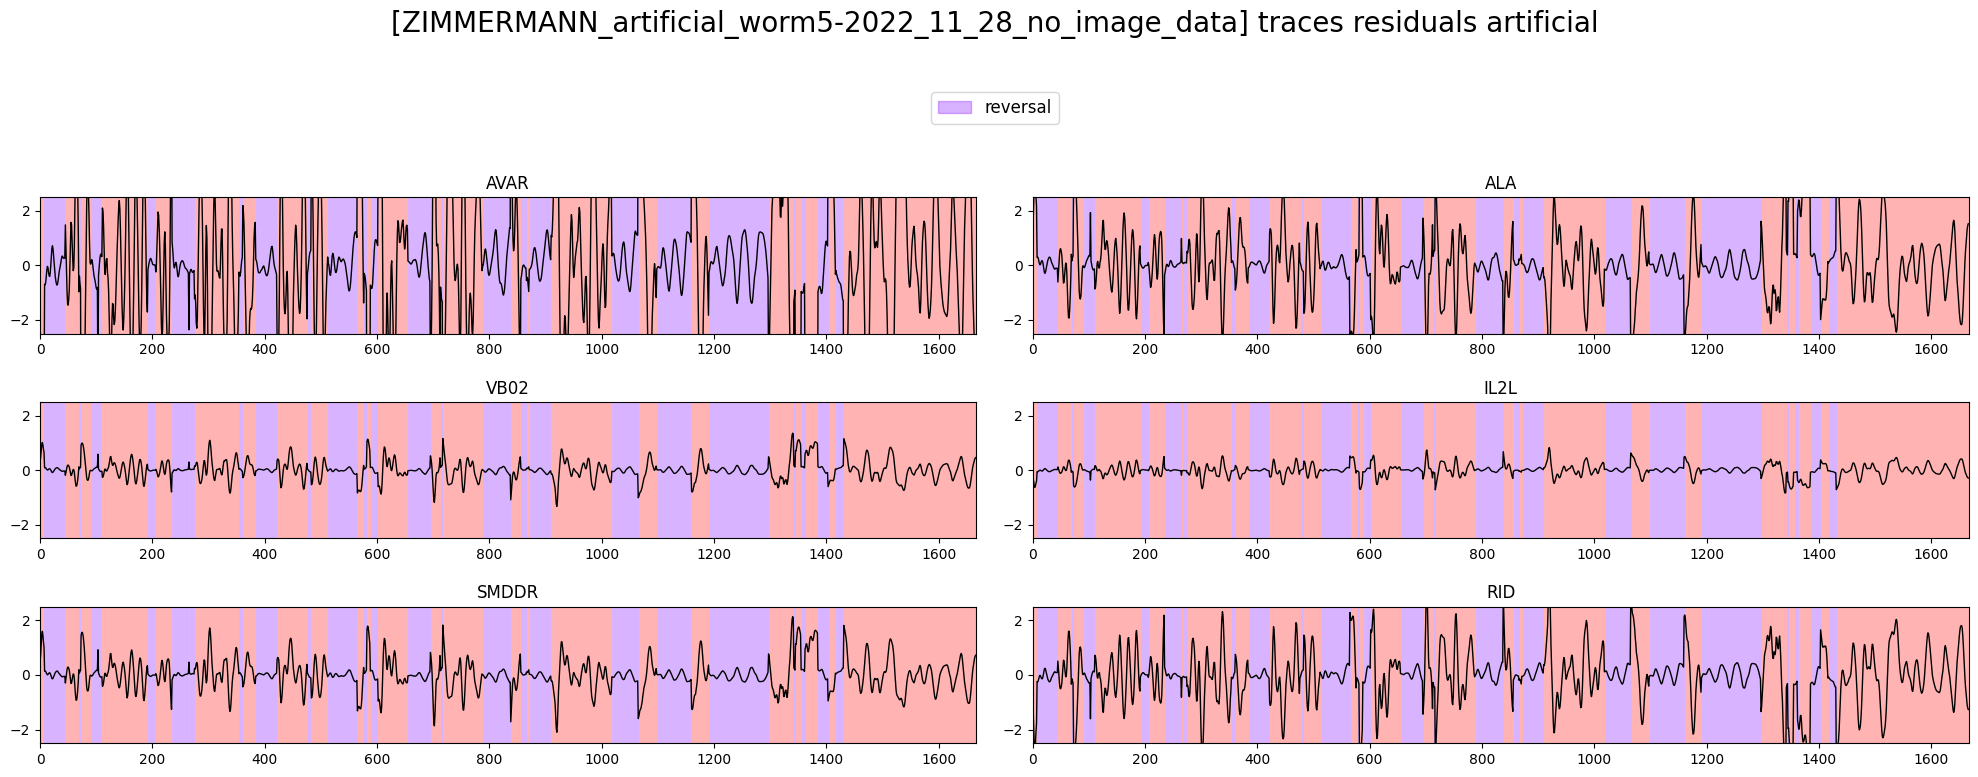

In [10]:
plot_utils.plot_traces(f'[{filenames_art[worm_id]}] traces residuals artificial',
					   traces_residual_art[worm_id][selection_n],
					   discrete_states_art[worm_id]['REV'],
					   n_plots=None, plots_per_row=2, ylimits=(-2.5, 2.5))

In [ ]:
# train clm art

(clm_models_params_art,
 clm_models_scores_art,
 clm_models_losses_art, clm_models_losses_tr_art,
 clm_models_mse_losses_art, clm_models_mse_losses_tr_art,
 __clm_models_grads_art) = train_joint_models(clm,
											  filenames_art,
											  discrete_states_art,
											  eigenworms_art,
											  traces_art)

1/1: ZIMMERMANN_artificial_worm5-2022_11_28_no_image_data  

In [38]:
# train hgm art

(hgm_models_params_art,
 hgm_models_scores_art,
 hgm_models_losses_art, hgm_models_losses_tr_art,
 hgm_models_mse_losses_art, hgm_models_mse_losses_tr_art,
 __hgm_models_grads_art) = train_joint_models(hgm,
											  filenames_art,
											  discrete_states_art,
											  eigenworms_art,
											  traces_art)

1/1: ZIMMERMANN_artificial_worm5-2022_11_28_no_image_data  

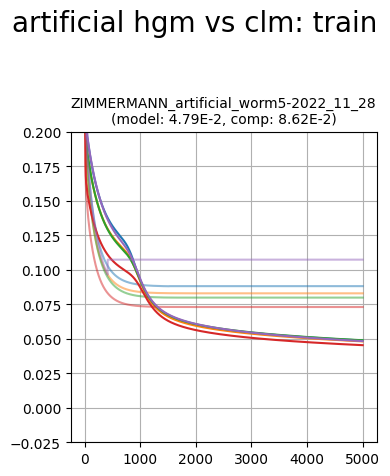

In [50]:
plot_utils.plot_losses_splits('artificial hgm vs clm: train',
							  filenames_art,
							  hgm_models_losses_tr_art, clm_models_losses_tr_art,
							  n_plots=None, plots_per_row=1, ylimits=(-0.01, 0.2))

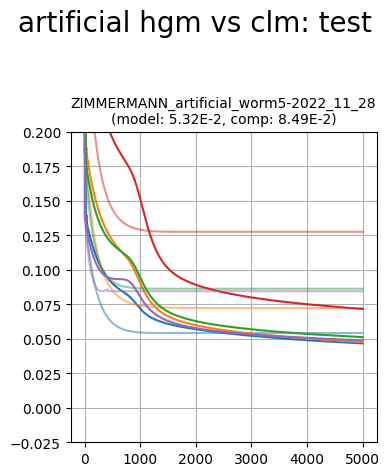

In [49]:
plot_utils.plot_losses_splits('artificial hgm vs clm: test',
							  filenames_art,
							  hgm_models_losses_art, clm_models_losses_art,
							  n_plots=None, plots_per_row=1, ylimits=(-0.01, 0.2))

In [41]:
def predict_wrapper(model, N, B_ll, params):
	N_res_pred, N_res, N_rec = model.obtain(params,
											N, B_ll,
											PrepData(
												N_mean=tuple((map(float, N.mean(axis=0)))),
												N_std=tuple((map(float, jnp.where((N_std := jnp.std(N, axis=0)) == 0.0, 1.0, N_std)))),
											))
	return N_res_pred, N_res, N_rec

clm_predicted_traces = [[pd.DataFrame(data=predict_wrapper(clm, jnp.array(traces_art[i]), jnp.array(eigenworms_art[i]), params)[0],
									  columns=traces_art[i].columns) for params in clm_models_params_art[i]] for i in range(len(traces_art))]
clm_defined_traces = [[pd.DataFrame(data=predict_wrapper(clm, jnp.array(traces_art[i]), jnp.array(eigenworms_art[i]), params)[1],
									columns=traces_art[i].columns) for params in clm_models_params_art[i]] for i in range(len(traces_art))]
clm_man_traces = [[pd.DataFrame(data=predict_wrapper(clm, jnp.array(traces_art[i]), jnp.array(eigenworms_art[i]), params)[2],
								columns=traces_art[i].columns) for params in clm_models_params_art[i]] for i in range(len(traces_art))]

hgm_predicted_traces = [[pd.DataFrame(data=predict_wrapper(hgm, jnp.array(traces_art[i]), jnp.array(eigenworms_art[i]), params)[0],
									  columns=traces_art[i].columns) for params in hgm_models_params_art[i]] for i in range(len(traces_art))]
hgm_defined_traces = [[pd.DataFrame(data=predict_wrapper(hgm, jnp.array(traces_art[i]), jnp.array(eigenworms_art[i]), params)[1],
									columns=traces_art[i].columns) for params in hgm_models_params_art[i]] for i in range(len(traces_art))]
hgm_man_traces = [[pd.DataFrame(data=predict_wrapper(hgm, jnp.array(traces_art[i]), jnp.array(eigenworms_art[i]), params)[2],
								columns=traces_art[i].columns) for params in hgm_models_params_art[i]] for i in range(len(traces_art))]

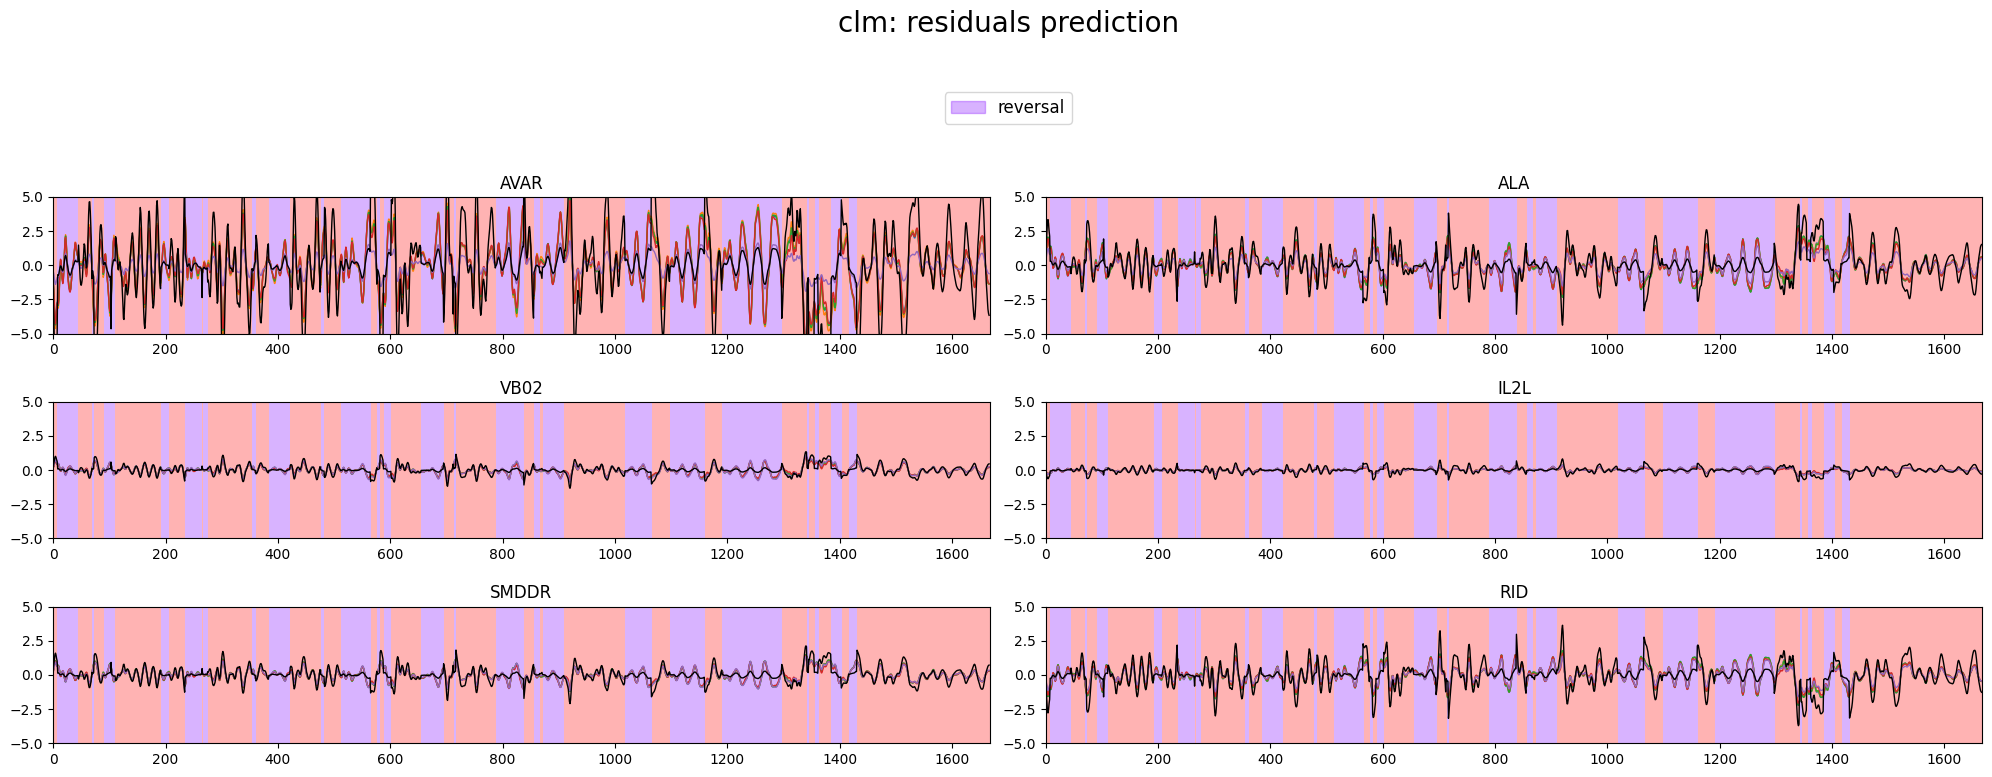

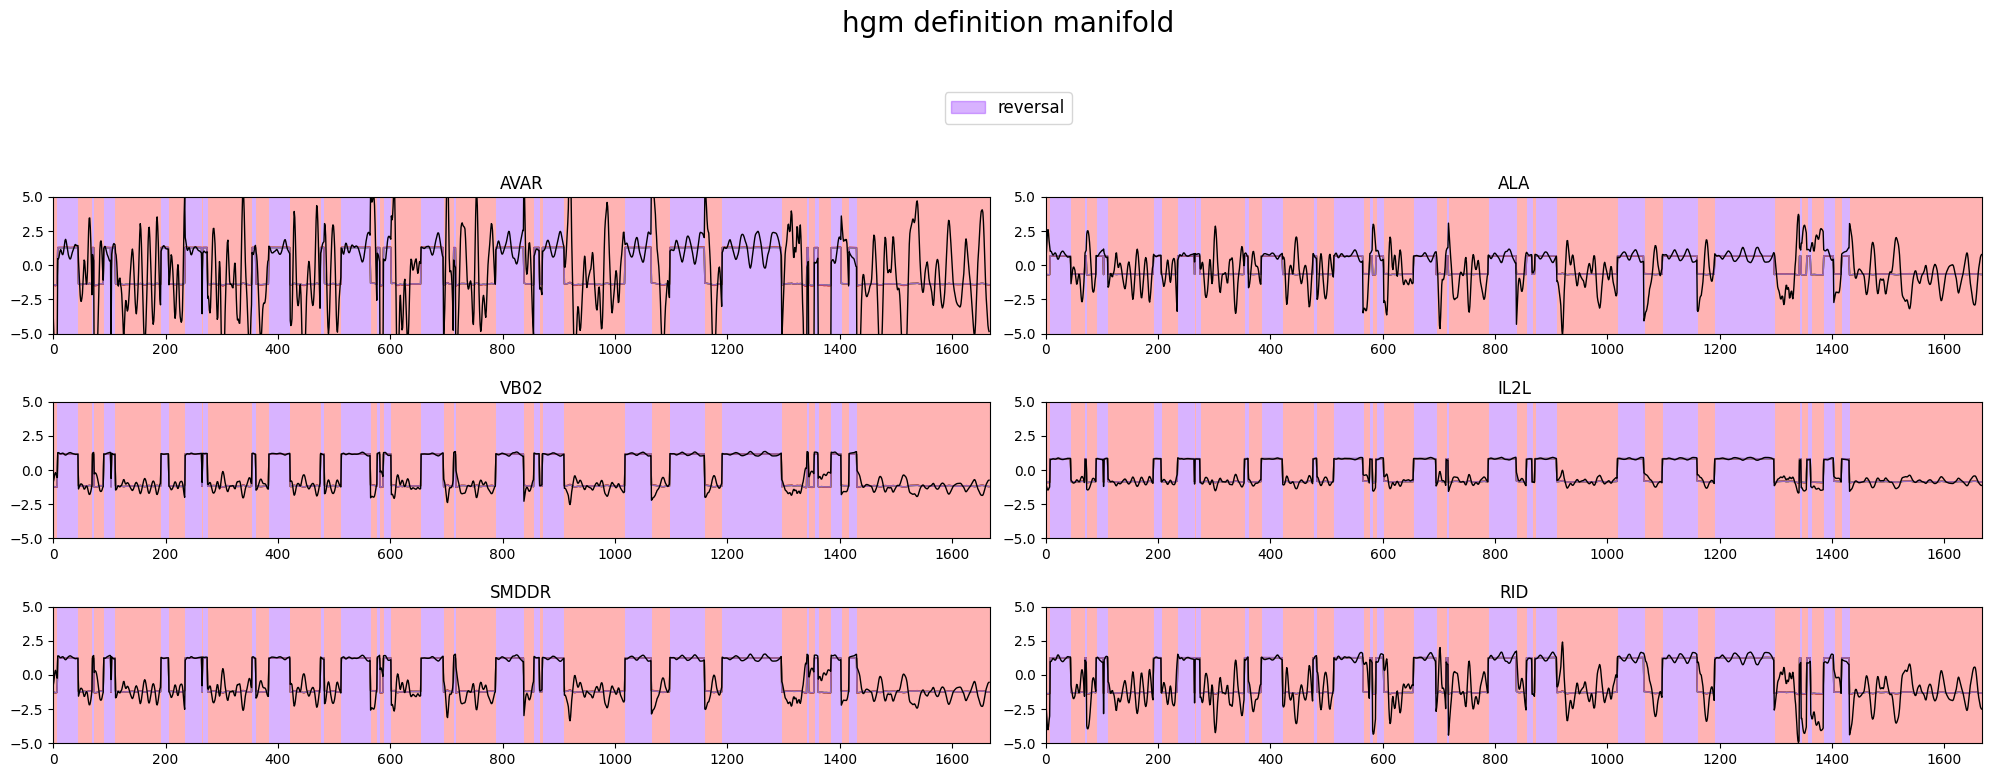

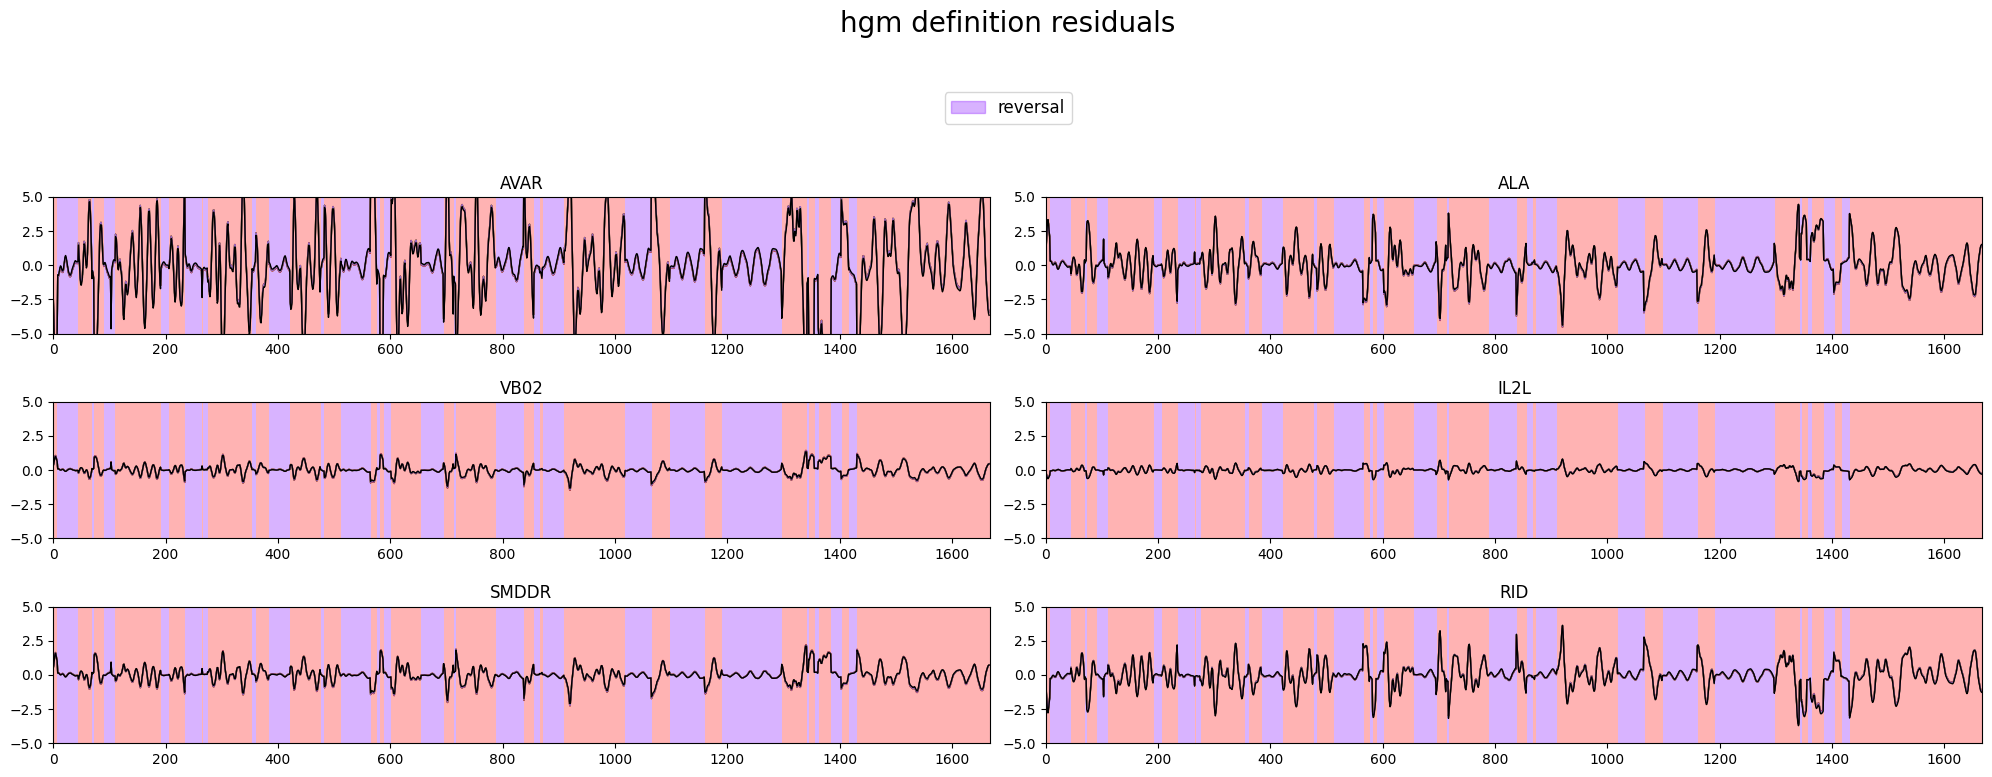

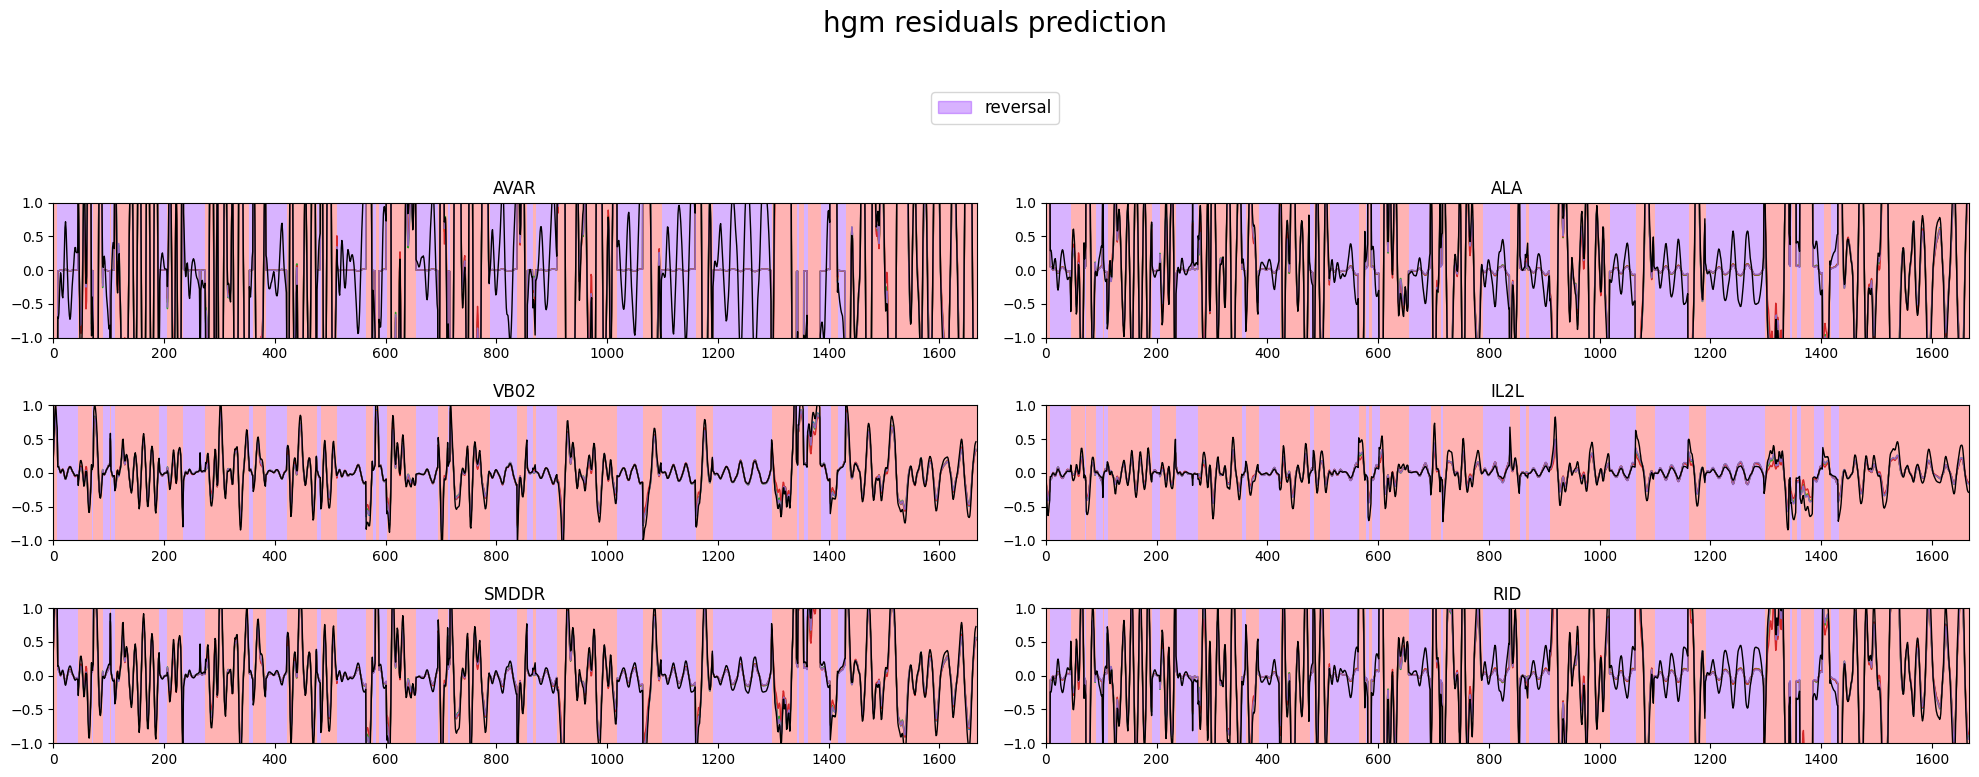

In [48]:
# plot_utils.plot_traces_splits('clm: definition manifold',
# 							  discrete_states_art[worm_id]['REV'],
# 							  traces_art[worm_id][selection_n], clm_man_traces[worm_id],
# 							  ylimits=(-5, 5))
# plot_utils.plot_traces_splits('clm: definition residuals',
# 							  discrete_states_art[worm_id]['REV'],
# 							  traces_residual_art[worm_id][selection_n], clm_defined_traces[worm_id],
# 							  ylimits=(-5, 5))
plot_utils.plot_traces_splits('clm: residuals prediction',
							  discrete_states_art[worm_id]['REV'],
							  traces_residual_art[worm_id][selection_n], clm_predicted_traces[worm_id],
							  ylimits=(-5, 5))

plot_utils.plot_traces_splits('hgm definition manifold',
							  discrete_states_art[worm_id]['REV'],
							  traces_art[worm_id][selection_n], hgm_man_traces[worm_id],
							  ylimits=(-5, 5))
plot_utils.plot_traces_splits('hgm definition residuals',
							  discrete_states_art[worm_id]['REV'],
							  traces_residual_art[worm_id][selection_n], hgm_defined_traces[worm_id],
							  ylimits=(-5, 5))
plot_utils.plot_traces_splits('hgm residuals prediction',
							  discrete_states_art[worm_id]['REV'],
							  traces_residual_art[worm_id][selection_n], hgm_predicted_traces[worm_id],
							  plot_init=True,  ylimits=(-1, 1))

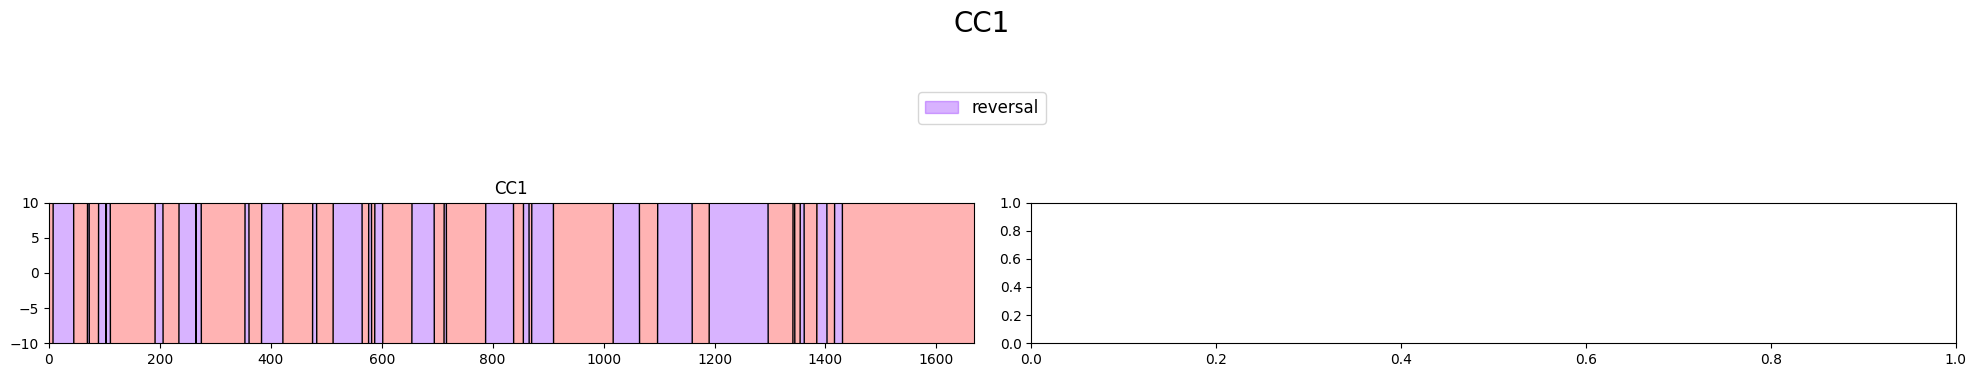

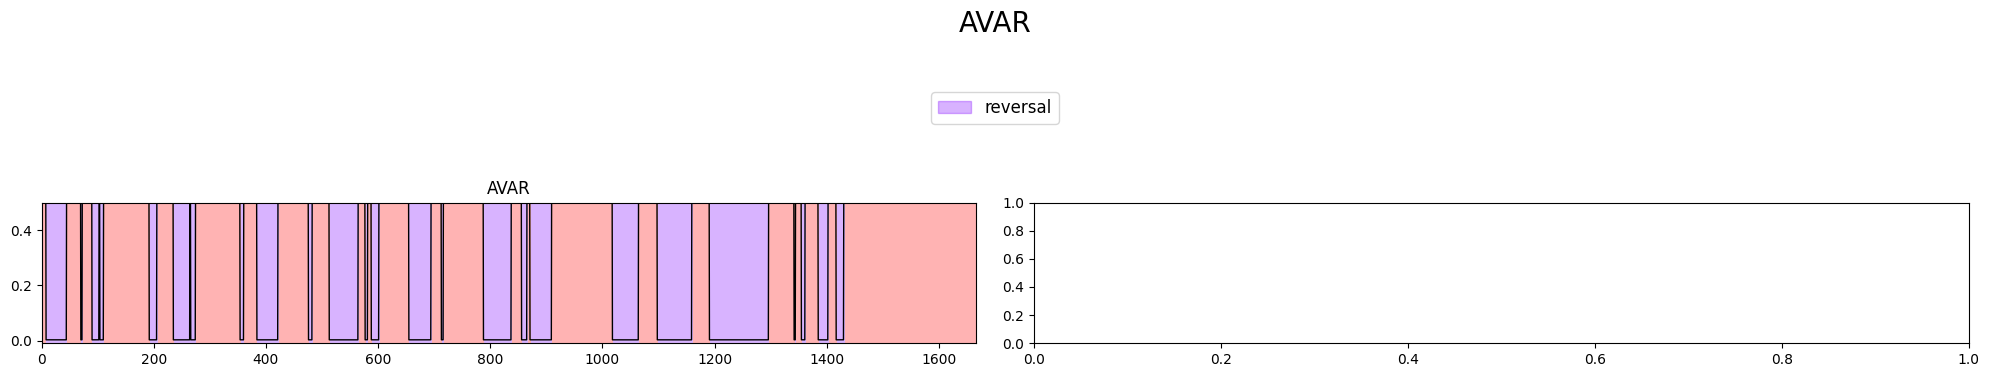

In [43]:
def predict_wrapper2(model, N, B_ll, params):
	N_res_pred, N_res, N_rec, (N_man, linterm, sigterm) = model.obtain2(params,
											N, B_ll,
											PrepData(
												N_mean=tuple((map(float, N.mean(axis=0)))),
												N_std=tuple((map(float, jnp.where((N_std := jnp.std(N, axis=0)) == 0.0, 1.0, N_std)))),
											))
	return np.array(N_res_pred), np.array(N_res), np.array(N_rec), (np.array(N_man), np.array(linterm), np.array(sigterm))


split_id = 2

hgm_stuff = [predict_wrapper2(hgm, np.array(traces_art[0]), np.array(eigenworms_art[0]), params) for params in hgm_models_params_art[0]]
TEMP_N_res_pred, TEMP_N_res, TEMP_N_rec, (TEMP_N_man, TEMP_linterm, TEMP_sigterm) = hgm_stuff[split_id]

TEMP_N_res_pred = pd.DataFrame(data=TEMP_N_res_pred, columns=traces_art[0].columns)
TEMP_N_res = pd.DataFrame(data=TEMP_N_res, columns=traces_art[0].columns)
TEMP_N_rec = pd.DataFrame(data=TEMP_N_rec, columns=traces_art[0].columns)
TEMP_N_man = pd.DataFrame(data=TEMP_N_man, columns=['CC1'])
TEMP_linterm = pd.DataFrame(data=TEMP_linterm, columns=traces_art[0].columns)
TEMP_sigterm = pd.DataFrame(data=TEMP_sigterm, columns=traces_art[0].columns)


p2 = pd.DataFrame(data=TEMP_linterm.values * TEMP_sigterm.values, columns=traces_residual_art[0].columns)
plot_utils.plot_traces('CC1',
					   # [TEMP_linterm, TEMP_sigterm, p2, TEMP_N_res_pred],
					   [TEMP_N_man],
					   discrete_states_art[worm_id]['REV'],
					   keys=['CC1'],
					   n_plots=1, ylimits=(-10, 10))

plot_utils.plot_traces('AVAR',
					   [TEMP_sigterm], # TEMP_N_res_pred, TEMP_linterm,
					   discrete_states_art[worm_id]['REV'],
					   keys=['AVAR'],
					   n_plots=1, ylimits=(-0.01, 0.5))

In [44]:
# assemble_art

neuron_scores_art = assemble(filenames_art, traces_art, clm_models_scores_art, hgm_models_scores_art)

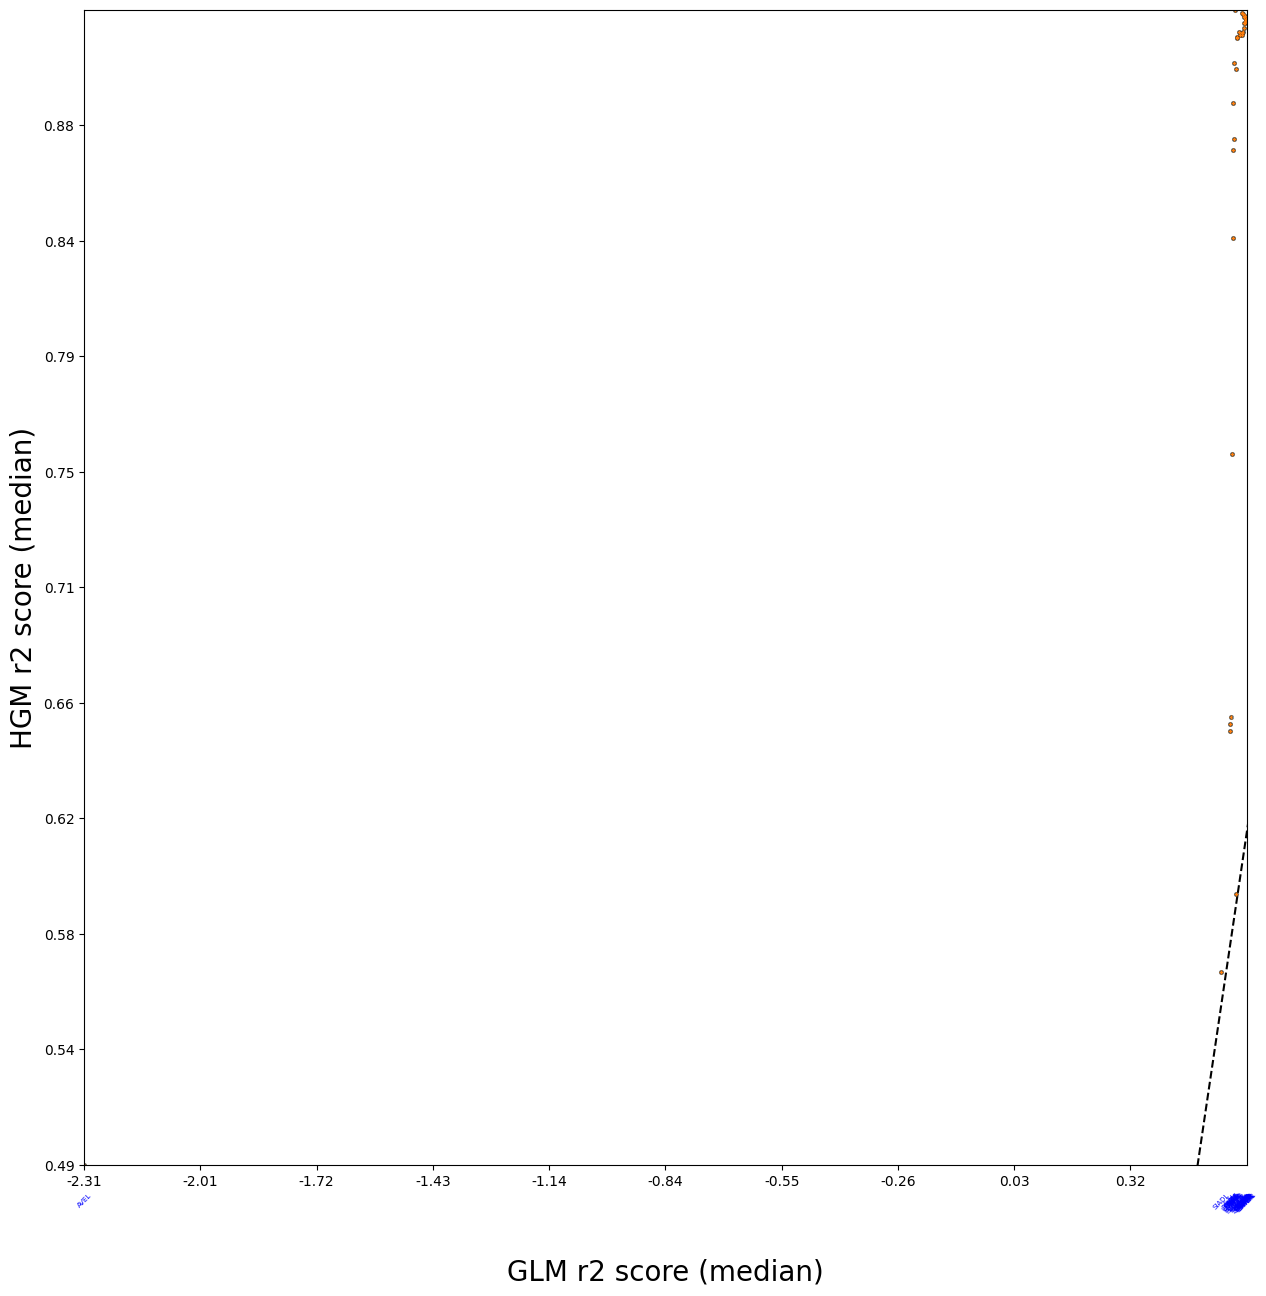

In [45]:
plot_utils.plot_performance_plot(neuron_scores_art, None)

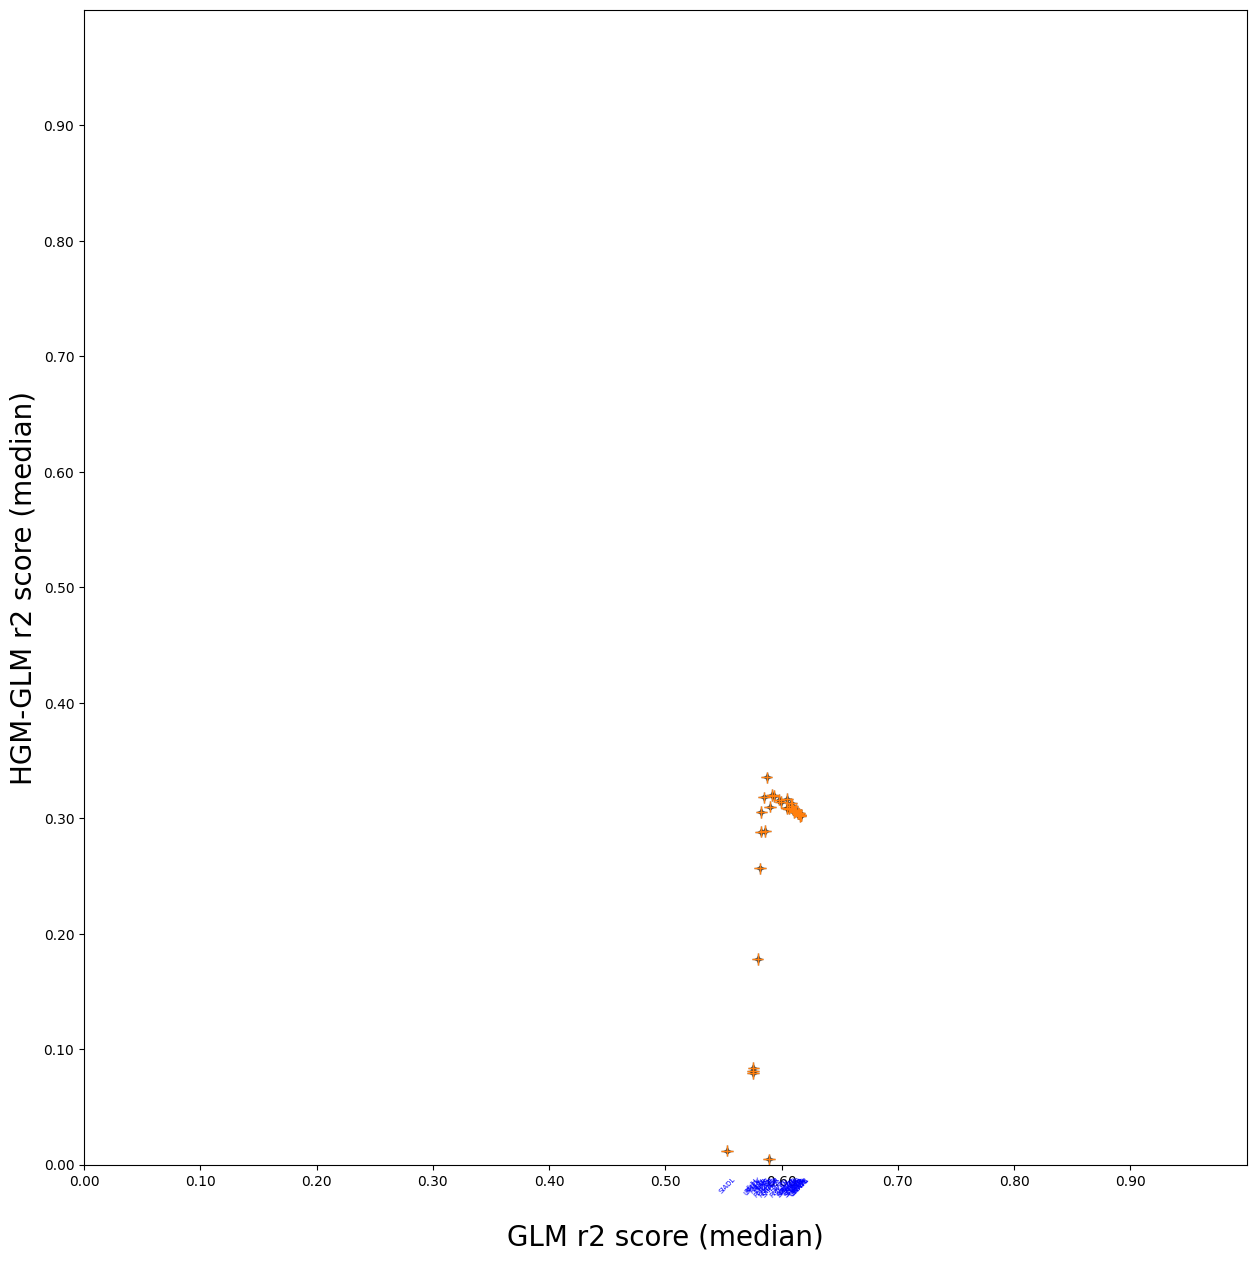

In [46]:
plot_utils.plot_improvement_plot(neuron_scores_art, None, limits=(0, 1, 0, 1))

# ARTIFICIAL DATA END

In [47]:
if True: raise Exception

Exception: 

# GCAMP

### CLM

In [22]:
(clm_models_params_gcamp,
 clm_models_scores_gcamp,
 clm_models_losses_gcamp, clm_models_losses_tr_gcamp,
 clm_models_mse_losses_gcamp, clm_models_mse_losses_tr_gcamp,
 __clm_models_grads_gcamp) = train_joint_models(clm,
												filenames_gcamp,
												discrete_states_gcamp,
												eigenworms_gcamp,
												traces_gcamp)

1/1: ZIM2165_Gcamp7b_worm5-2022_11_28_no_image_data  

### HGM

In [23]:
(hgm_models_params_gcamp,
 hgm_models_scores_gcamp,
 hgm_models_losses_gcamp, hgm_models_losses_tr_gcamp,
 hgm_models_mse_losses_gcamp, hgm_models_mse_losses_tr,
 __hgm_models_grads_gcamp) = train_joint_models(hgm,
												filenames_gcamp,
												discrete_states_gcamp,
												eigenworms_gcamp,
												traces_gcamp)

1/1: ZIM2165_Gcamp7b_worm5-2022_11_28_no_image_data  

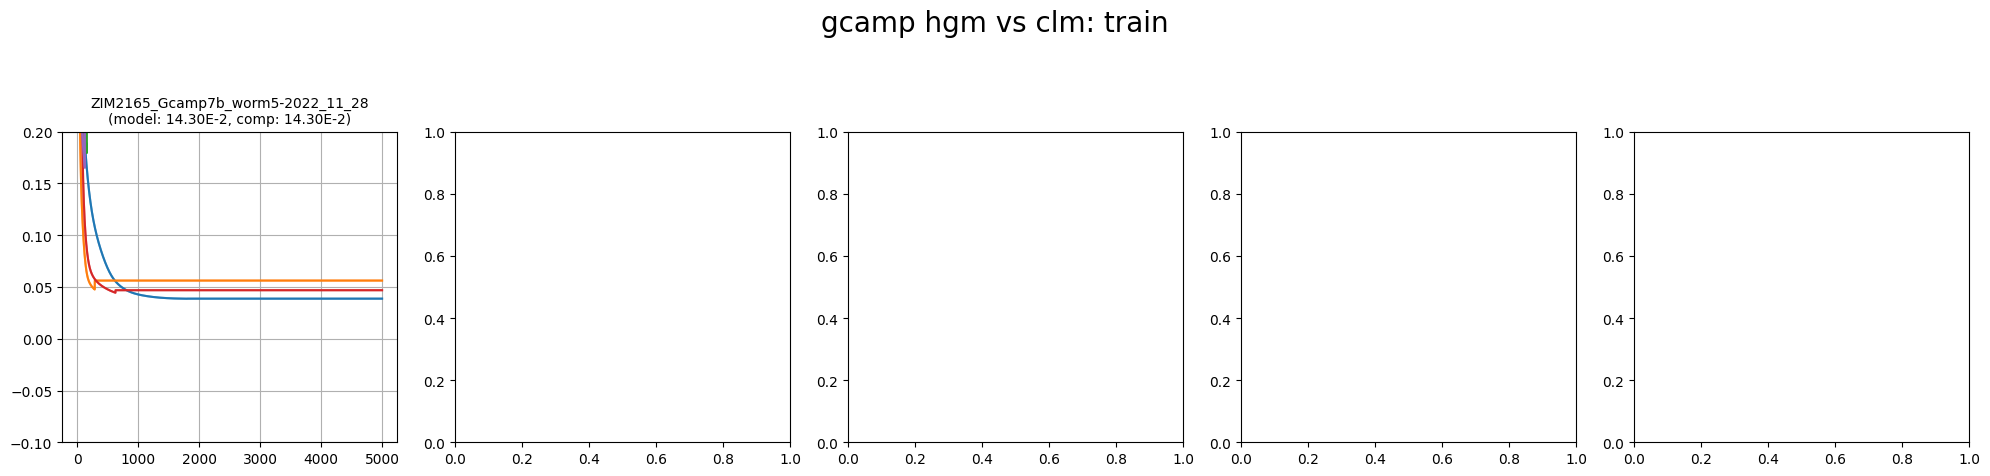

In [24]:
plot_utils.plot_losses_splits('gcamp hgm vs clm: train',
							  filenames_gcamp,
							  hgm_models_losses_tr_gcamp, clm_models_losses_tr_gcamp,
							  n_plots=None, ylimits=(-0.1, 0.2))

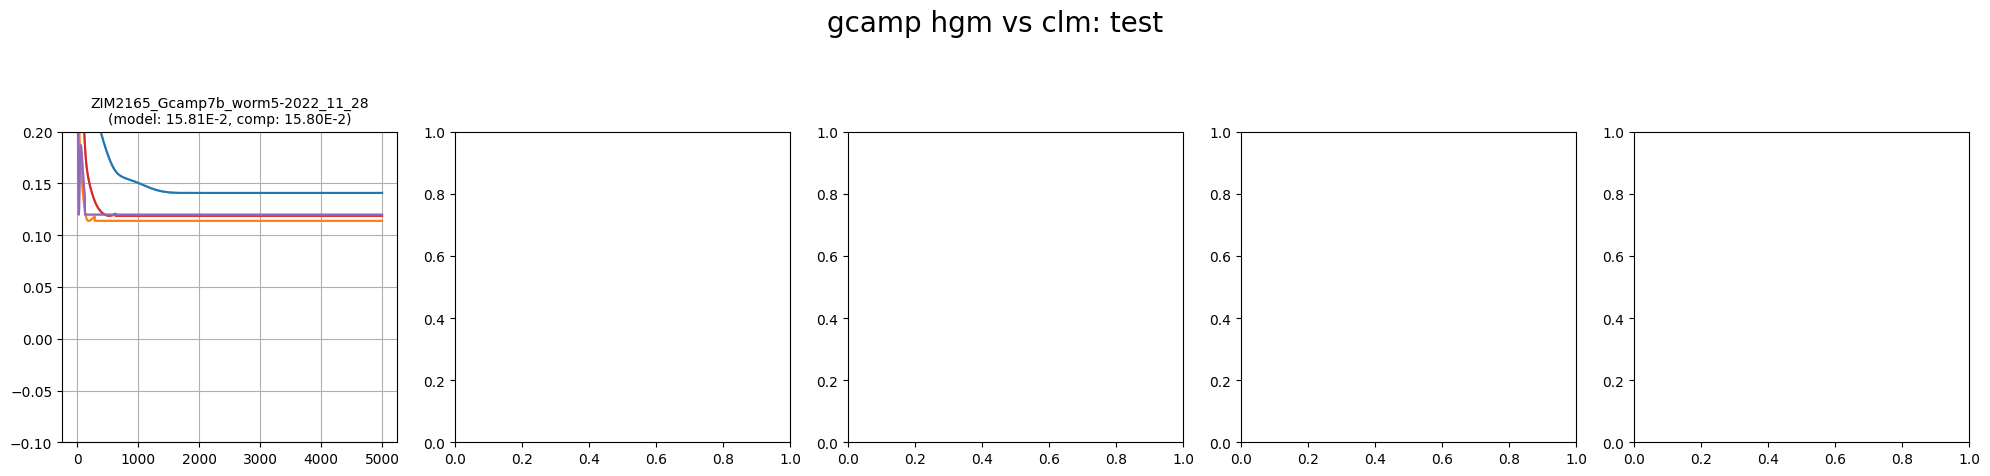

In [25]:
plot_utils.plot_losses_splits('gcamp hgm vs clm: test',
							  filenames_gcamp,
							  hgm_models_losses_gcamp, clm_models_losses_gcamp,
							  n_plots=None, ylimits=(-0.1, 0.2))

In [26]:
def predict_wrapper(model, N, B_ll, params):
	N_mean = N.mean(axis=0)
	N_std = N.std(axis=0)
	N_std[N_std == 0.0] = 1.0
	N_zs = (N - N_mean) / N_std

	N_man = N_zs @ params['U']
	N_zs_rec = N_man @ jnp.linalg.inv(N_man.T @ N_man) @ N_man.T @ N_zs	# got'em	N_man @ jax.numpy.linalg.pinv(U)
	N_rec = N_zs_rec * N_std + N_mean
	N_res = N - N_rec

	if model.get_type():
		Y_pred = model.predict(B_ll, N_man, params['W1'], params['W2'])
	else:
		Y_pred = model.predict(B_ll, params['W'])

	return Y_pred, N_res, N_rec


clm_predicted_traces = [[pd.DataFrame(data=predict_wrapper(clm, jnp.array(traces_art[i]), jnp.array(eigenworms_art[i]), params)[0], columns=traces_art[i].columns) for params in clm_models_params_art[i]] for i in range(len(traces_art))]
clm_defined_traces = [[pd.DataFrame(data=predict_wrapper(clm, jnp.array(traces_art[i]), jnp.array(eigenworms_art[i]), params)[1], columns=traces_art[i].columns) for params in clm_models_params_art[i]] for i in range(len(traces_art))]
clm_man_traces = [[pd.DataFrame(data=predict_wrapper(clm, jnp.array(traces_art[i]), jnp.array(eigenworms_art[i]), params)[2], columns=traces_art[i].columns) for params in clm_models_params_art[i]] for i in range(len(traces_art))]

hgm_predicted_traces = [[pd.DataFrame(data=predict_wrapper(hgm, jnp.array(traces_art[i]), jnp.array(eigenworms_art[i]), params)[0], columns=traces_art[i].columns) for params in hgm_models_params_art[i]] for i in range(len(traces_art))]
hgm_defined_traces = [[pd.DataFrame(data=predict_wrapper(hgm, jnp.array(traces_art[i]), jnp.array(eigenworms_art[i]), params)[1], columns=traces_art[i].columns) for params in hgm_models_params_art[i]] for i in range(len(traces_art))]
hgm_man_traces = [[pd.DataFrame(data=predict_wrapper(hgm, jnp.array(traces_art[i]), jnp.array(eigenworms_art[i]), params)[2], columns=traces_art[i].columns) for params in hgm_models_params_art[i]] for i in range(len(traces_art))]

TypeError: JAX arrays are immutable and do not support in-place item assignment. Instead of x[idx] = y, use x = x.at[idx].set(y) or another .at[] method: https://docs.jax.dev/en/latest/_autosummary/jax.numpy.ndarray.at.html

In [ ]:
plot_utils.plot_traces_splits('clm: manifold',
							  discrete_states_gcamp[worm_id]['REV'],
							  traces_gcamp[worm_id][selection_n], clm_man_traces[worm_id],
							  n_plots=None, plots_per_row=1, ylimits=None)
plot_utils.plot_traces_splits('clm: definitions',
							  discrete_states_gcamp[worm_id]['REV'],
							  traces_gcamp[worm_id][selection_n], clm_defined_traces[worm_id],
							  n_plots=None, plots_per_row=1, ylimits=None)
plot_utils.plot_traces_splits('clm: predictions',
							  discrete_states_gcamp[worm_id]['REV'],
							  traces_gcamp[worm_id][selection_n], clm_predicted_traces[worm_id],
							  n_plots=None, plots_per_row=1, ylimits=None)

plot_utils.plot_traces_splits('hgm manifold',
							  discrete_states_gcamp[worm_id]['REV'],
							  traces_gcamp[worm_id][selection_n], hgm_man_traces[worm_id],
							  n_plots=None, plots_per_row=1, ylimits=None)
plot_utils.plot_traces_splits('hgm definitions',
							  discrete_states_gcamp[worm_id]['REV'],
							  traces_gcamp[worm_id][selection_n], hgm_defined_traces[worm_id],
							  n_plots=None, plots_per_row=1, ylimits=None)
plot_utils.plot_traces_splits('hgm predictions',
							  discrete_states_gcamp[worm_id]['REV'],
							  traces_gcamp[worm_id][selection_n], hgm_predicted_traces[worm_id],
							  n_plots=None, plots_per_row=1, ylimits=None)

### __loss gradient per weights over time

In [ ]:
# fig, axes = plt.subplots(1, 2, figsize=(12, 3))
# for ax in axes:
#     ax.set_ylim(-0.005, 0.004)
#
# for i in range(1):
# 	gradsW = np.array([val['W'] for val in __clm_models_grads_gcamp[-1][i]])
#
# 	gradsW1 = np.array([val['W1'] for val in __hgm_models_grads_gcamp[-1][i]])
# 	gradsW2 = np.array([val['W2'] for val in __hgm_models_grads_gcamp[-1][i]])
#
#
# 	axes[0].plot(np.mean(gradsW1, axis=1))
#
# 	# axes[1].plot(np.mean(gradsW1, axis=1))
# 	axes[1].plot(np.mean(gradsW2, axis=1))

# GFP

### CLM

In [ ]:
(clm_models_params_gfp,
 clm_models_scores_gfp,
 clm_models_losses_gfp, clm_models_losses_tr_gfp,
 clm_models_mse_losses_gfp, clm_models_mse_losses_tr,
 __clm_models_grads_gfp) = train_joint_models(clm,
											  filenames_gfp,
											  discrete_states_gfp,
											  eigenworms_gfp,
											  traces_gfp)

### HGM

In [ ]:
(hgm_models_params_gfp,
 hgm_models_scores_gfp,
 hgm_models_losses_gfp, hgm_models_losses_tr_gfp,
 hgm_models_mse_losses_gfp, hgm_models_mse_losses_tr_gfp,
 __hgm_models_grads_gfp) = train_joint_models(hgm,
											  filenames_gfp,
											  discrete_states_gfp,
											  eigenworms_gfp,
											  traces_gfp)

In [ ]:
plot_utils.plot_losses_splits('gfp hgm vs clm: train',
							  filenames_gfp,
							  hgm_models_losses_tr_gfp, clm_models_losses_tr_gfp,
							  n_plots=None, ylimits=None)

In [ ]:
plot_utils.plot_losses_splits('gfp hgm vs clm: test',
							  filenames_gfp,
							  hgm_models_losses_gfp, clm_models_losses_gfp,
							  n_plots=None, ylimits=None)

# assemble

In [ ]:
neuron_scores_gcamp = assemble(filenames_gcamp, traces_gcamp, clm_models_scores_gcamp, hgm_models_scores_gcamp)
neuron_scores_gfp = assemble(filenames_gfp, traces_gfp, clm_models_scores_gfp, hgm_models_scores_gfp)

# Plot

In [ ]:
plot_utils.plot_performance_plot(neuron_scores_gcamp, neuron_scores_gfp, limits=(-0.5, 0.3, -1.1, 0.4))

In [ ]:
plot_utils.plot_improvement_plot(neuron_scores_gcamp, neuron_scores_gfp, limits=(-1, 0.5, -0.3, 1))